# 06d: Deep Learning Sweep -- Duration (F-DATA and PM100)

This is one of six notebooks covering the deep-learning (FNN/LSTM/TCN) side of this thesis:

- `06a_sequence_investigation.ipynb` -- jobs-per-user distribution, the sequence-length choice, padding policy, the sequence-construction leakage test, and F-DATA/PM100 lag-1 autocorrelation; also holds the deep-learning feature-set explanation shared by the notebooks below.
- `06b_model_architectures.ipynb` -- the FNN/SequenceLSTM/SequenceTCN/`_CausalConvBlock`/FlatDataset/SequenceDataset class definitions, documented layer by layer, an equivalence check against `src/models.py`, architecture diagrams, the training configuration, and a checkpoint-match check across all 18 (combination, architecture) pairs.
- `06c_dl_power.ipynb` -- the real FNN/LSTM/TCN sweep for F-DATA power and PM100 power.
- `06d_dl_duration.ipynb` -- the same for F-DATA duration and PM100 duration.
- `06e_dl_memory.ipynb` -- the same for F-DATA memory and PM100 memory (`pm100_memory_c4`).
- `06f_dl_comparison.ipynb` -- the F-DATA duration/memory raw-space collapse diagnostic (including the three-user inspection), the same-features classical-ML control, and the six-combination summary against classical ML.

**The DL feature set is not identical to classical ML's (05/05b/05c).** Three column families are dropped for the DL models specifically, scoped to the deep-learning pipeline only -- classical ML's own already-adopted results are untouched:
- Absolute epoch-timestamp columns (`adt_epoch`/`qdt_epoch`/`schedsdt_epoch` for F-DATA, `submit_time_epoch`/`eligible_time_epoch` for PM100) -- standardized on tune_train, a chronologically-later test period's values land several std devs out of range, which a standardized neural net cannot extrapolate through (trees tolerate this fine via boundary splits).
- Per-split `pd.factorize()`-coded categorical columns (`jobenv_req_code` for F-DATA; `partition_code`/`qos_code`/`shared_code`/`group_id_code` for PM100) -- the integer code is order-of-first-appearance WITHIN each split, so the same real category can get a different code in train vs test. Replaced, not just dropped: one-hot encoded instead, fit on the train+test population combined so both splits get identical dummy columns.
- Per-split user-frequency columns (`usr_freq` for F-DATA, `user_id_freq` for PM100) -- same issue class, a user's test-period job count has nothing to do with their train-period count.

See `src/dl_data.py`'s `load_combo` for the real implementation of all three.

Every cell below reproduces the real pipeline that originally produced these results: data loading, feature treatment (epoch-timestamp/frequency columns dropped, factorize codes replaced with train+test-combined one-hot -- see `06a_sequence_investigation.ipynb`), standardization fit on `tune_train` only, sequence construction for LSTM/TCN, model definition (`src/models.py`, via `src/dl_pipeline.py`), a 10-trial Optuna search over learning rate, and evaluation on the real held-out TEST split. Nothing here is read from a static results table alone.

**What is reused, and why, stated plainly (same convention as notebook 05's `SKIP_TUNING`):** the original 18-pair sweep ran as detached systemd services over ~20.5 hours across 4 GPUs, not inside any notebook. Optuna's persistent SQLite storage means every `run_pair` call below checks how many trials already completed first and only runs the remainder -- with all 18 pairs already at 10/10 completed trials, every call here does zero additional training and the final evaluation reloads each pair's own saved checkpoint directly. Re-running this notebook top to bottom costs real data-loading and one test-set forward pass per (combination, architecture) pair -- a few seconds for PM100, a few minutes for F-DATA's larger sequence construction -- not a fresh 20-hour search. If a study were ever found incomplete, the exact same cell would transparently run the real remaining trials instead.

In [1]:
import warnings
warnings.filterwarnings("ignore", message="IProgress not found")

import sys
sys.path.append("..")

import pathlib
import time

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from src import plotting
from src.dl_pipeline import (prepare_combo_data, run_pair, save_pair_artifacts,
                              append_dim_row, ARCHITECTURES)

pd.set_option("display.width", 160)
FIGURES_DIR = pathlib.Path("figures")
FIGURES_DIR.mkdir(exist_ok=True)

all_results = {}  # combo -> {arch -> result dict}, filled in by each Part below


## F-DATA duration

In [2]:
PART_COMBO = "fdata_duration"
prepared = prepare_combo_data(PART_COMBO)
part_results = {}
for arch in ARCHITECTURES:
    t0 = time.perf_counter()
    part_results[arch] = run_pair(prepared, arch)
    r = part_results[arch]
    print(f"  {arch}: best_trial=#{r['best_trial']} best_lr={r['best_lr']:.2e} "
          f"({time.perf_counter() - t0:.1f}s)")
all_results[PART_COMBO] = part_results

for arch in ARCHITECTURES:
    save_pair_artifacts(PART_COMBO, arch, prepared, part_results[arch])
append_dim_row(PART_COMBO, prepared["X_full_df"].shape[1])

raw_df = pd.DataFrame({a: part_results[a]["raw_metrics"] for a in part_results}).T
log_df = pd.DataFrame({a: part_results[a]["log_metrics"] for a in part_results}).T
print(f"\nRESULTS -- F-DATA duration, TEST split (n={len(prepared['y_test_raw']):,})")
print("\nRaw-space metrics:")
display(raw_df.round(4))
print("\nLog-space metrics (back-transform check):")
display(log_df.drop(columns=["MAPE", "Within20pct"]).round(4))


[fdata] excluded 9.9% of jobs as non-completed (2558519 / 25866900)


fdata_duration: 16,315,867 train / 6,992,514 test rows; scaler log-transformed 12/95 columns; sequences built in 512s, fill rate 75.74%


[I 2026-11-01 19:20:27,801] Using an existing study with name 'fdata_duration_FNN' instead of creating a new one.


[I 2026-11-01 19:21:41,609] Using an existing study with name 'fdata_duration_LSTM' instead of creating a new one.


  FNN: best_trial=#8 best_lr=1.21e-04 (74.6s)


[I 2026-11-01 19:24:30,073] Using an existing study with name 'fdata_duration_TCN' instead of creating a new one.


... (2 outputs left out)


RESULTS -- F-DATA duration, TEST split (n=6,992,514)

Raw-space metrics:


,MAE,RMSE,R2,MAPE,MedAE,Within20pct
FNN,3993.1619,12546.1819,0.7661,1377.1893,416.8176,32.4278
LSTM,11754.3878,55550.1669,-3.5850,1236.3135,474.8135,30.0279
TCN,11153.4498,52636.5597,-3.1166,1708.9805,447.6608,30.3256



Log-space metrics (back-transform check):


,MAE,RMSE,R2,MedAE
FNN,0.5322,0.8749,0.8713,0.3631
LSTM,0.6478,1.0081,0.8291,0.4381
TCN,0.6229,0.9921,0.8345,0.4203


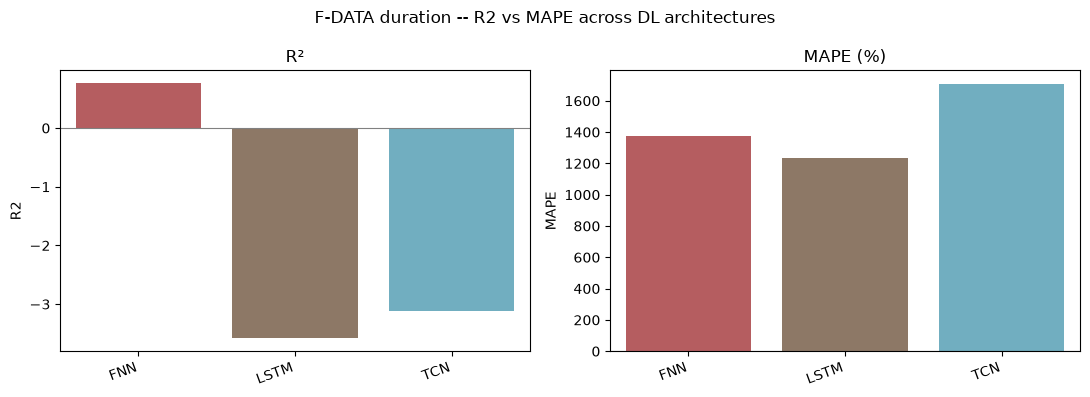

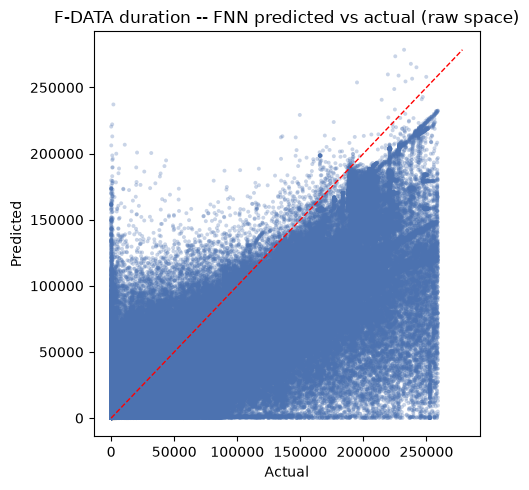

Best DL architecture for F-DATA duration: FNN (raw R2=0.7661)


In [3]:
fig = plotting.plot_model_comparison(raw_df, "F-DATA duration -- R2 vs MAPE across DL architectures")
fig.savefig(FIGURES_DIR / "notebook06_fdata_duration_dl_model_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

best_arch = raw_df["R2"].idxmax()
fig = plotting.plot_predicted_vs_actual(
    part_results[best_arch]["y_test_raw"], part_results[best_arch]["preds_raw"],
    f"F-DATA duration -- {best_arch} predicted vs actual (raw space)")
fig.savefig(FIGURES_DIR / f"notebook06_fdata_duration_{best_arch}_pred_vs_actual.png", dpi=150,
            bbox_inches="tight")
plt.show()
print(f"Best DL architecture for F-DATA duration: {best_arch} "
      f"(raw R2={raw_df.loc[best_arch, 'R2']:.4f})")


## PM100 duration

In [4]:
PART_COMBO = "pm100_duration"
prepared = prepare_combo_data(PART_COMBO)
part_results = {}
for arch in ARCHITECTURES:
    t0 = time.perf_counter()
    part_results[arch] = run_pair(prepared, arch)
    r = part_results[arch]
    print(f"  {arch}: best_trial=#{r['best_trial']} best_lr={r['best_lr']:.2e} "
          f"({time.perf_counter() - t0:.1f}s)")
all_results[PART_COMBO] = part_results

for arch in ARCHITECTURES:
    save_pair_artifacts(PART_COMBO, arch, prepared, part_results[arch])
append_dim_row(PART_COMBO, prepared["X_full_df"].shape[1])

raw_df = pd.DataFrame({a: part_results[a]["raw_metrics"] for a in part_results}).T
log_df = pd.DataFrame({a: part_results[a]["log_metrics"] for a in part_results}).T
print(f"\nRESULTS -- PM100 duration, TEST split (n={len(prepared['y_test_raw']):,})")
print("\nRaw-space metrics:")
display(raw_df.round(4))
print("\nLog-space metrics (back-transform check):")
display(log_df.drop(columns=["MAPE", "Within20pct"]).round(4))


[pm100] excluded 22.0% of jobs as non-completed (50928 / 231238)


[I 2026-11-01 19:28:47,659] Using an existing study with name 'pm100_duration_FNN' instead of creating a new one.


pm100_duration: 126,217 train / 54,093 test rows; scaler log-transformed 7/28 columns; sequences built in 2s, fill rate 71.58%


[I 2026-11-01 19:28:48,190] Using an existing study with name 'pm100_duration_LSTM' instead of creating a new one.


  FNN: best_trial=#0 best_lr=1.06e-04 (0.5s)


[I 2026-11-01 19:28:49,618] Using an existing study with name 'pm100_duration_TCN' instead of creating a new one.


  LSTM: best_trial=#9 best_lr=2.76e-04 (1.4s)


  TCN: best_trial=#8 best_lr=5.45e-04 (1.2s)

RESULTS -- PM100 duration, TEST split (n=54,093)

Raw-space metrics:


,MAE,RMSE,R2,MAPE,MedAE,Within20pct
FNN,1922.2932,7410.5104,0.6369,757.0522,12.6341,9.0588
LSTM,2206.0424,8797.9181,0.4881,591.1244,6.6894,9.8225
TCN,2268.1803,8894.9251,0.4768,566.4552,6.9831,8.6409



Log-space metrics (back-transform check):


,MAE,RMSE,R2,MedAE
FNN,1.2520,1.4539,0.8162,1.3506
LSTM,0.9270,1.1869,0.8775,0.8330
TCN,0.9925,1.2150,0.8717,0.9125


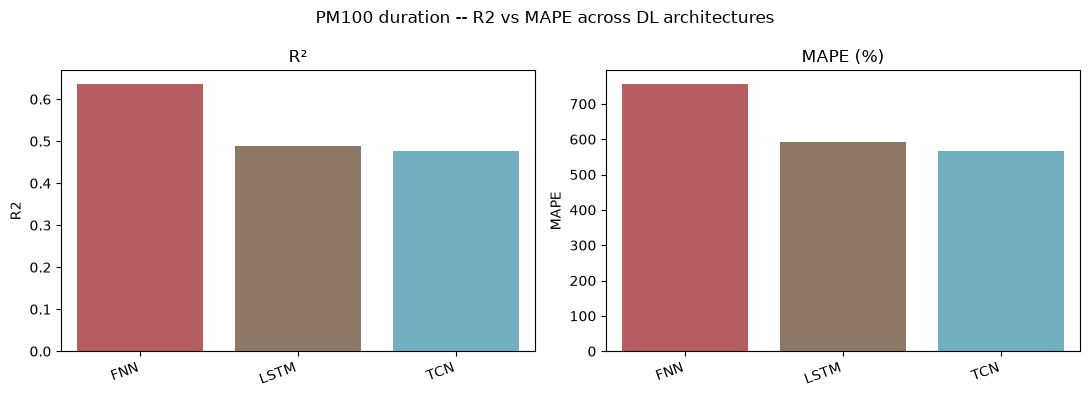

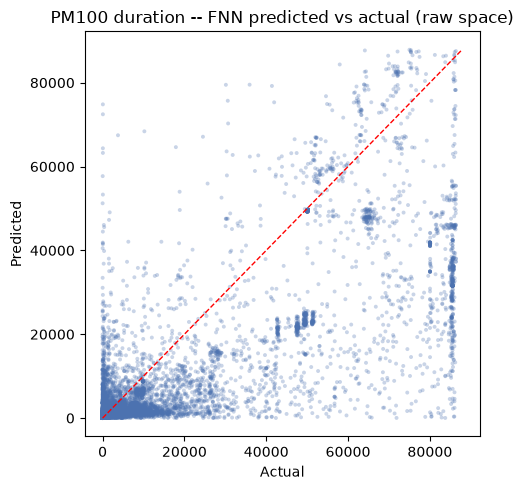

Best DL architecture for PM100 duration: FNN (raw R2=0.6369)


In [5]:
fig = plotting.plot_model_comparison(raw_df, "PM100 duration -- R2 vs MAPE across DL architectures")
fig.savefig(FIGURES_DIR / "notebook06_pm100_duration_dl_model_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

best_arch = raw_df["R2"].idxmax()
fig = plotting.plot_predicted_vs_actual(
    part_results[best_arch]["y_test_raw"], part_results[best_arch]["preds_raw"],
    f"PM100 duration -- {best_arch} predicted vs actual (raw space)")
fig.savefig(FIGURES_DIR / f"notebook06_pm100_duration_{best_arch}_pred_vs_actual.png", dpi=150,
            bbox_inches="tight")
plt.show()
print(f"Best DL architecture for PM100 duration: {best_arch} "
      f"(raw R2={raw_df.loc[best_arch, 'R2']:.4f})")
